# Lab 3: Bottom-Up Steel Emissions with Uncertainty


---

## What this lab is

* **Part A: emissions pipeline.** Same tasks, same order, same variable names as Lab 3: operating plants 2020-2030, China utilisation by technology, plant-level production, emission factors, company emissions, projection to 2030.
* **Part B : uncertainty quantification.** You will *interrogate* your own Lab 3 numbers with the tools of the Session 4 lecture: where do the numbers come from, how sure can we be, and what would a risk committee need to know?


## Learning goals

1. Rebuild a bottom-up emissions pipeline from plant-level data (Lab 3).
2. Tell **aleatoric, epistemic and scenario** uncertainty apart.
3. Spot a **data-coverage problem** by checking against official statistics.
4. Give a **range instead of a single number** (bootstrap and simulation) and find which input matters most.
5. Compare **scenarios** and communicate the result with calibrated words.

## Conventions

* Questions are **[QUAL]** (2-4 sentences) or **[QUANT]** (a number from your code plus one sentence).
* Write each answer in the cell right under the question.
* `ttpa` = thousand tonnes per annum. Emissions in Part A are in tCO2; in Part B we switch to **MtCO2**.
* Boxes marked **[OPTIONAL]** can be skipped.
* Run **Kernel -> Restart & Run All** before submitting.

## Submission

Work in **groups of up to 4**. Fill in every member before submitting.

1. Full name: Adem Ben Njima  Student ID: B00818393
2. Full name: Kenza Gueddas  Student ID: B00822443
3. Full name: Jawad Mallat  Student ID: B00820811
4. Full name: Erdem Sanver  Student ID: B00818169
5. Full name: Deha Tanaci Student ID: B00822530

**Group / repo name:** aidams-lab3-bennjima-gueddas-mallat-sanver-tanaci  
**Submitter (one person): Jawad Mallat**  
**Repo URL: https://github.com/Jawadmallat/aidams-lab3-bennjima-gueddas-mallat-sanver-tanaci.git**  

### What to submit

- This notebook (`lab3.ipynb`) with all tasks completed and cells run (outputs visible)
- A short `README.md` with how to run the notebook

Create a GitHub repo, push the notebook and README, invite the instructor, and paste the **repo URL** above.

**Send submission info to my email (1 email per group).** Include the GitHub repo URL.

**Done when:** all names are filled in and the notebook contains outputs (no need for the instructor to re-run it).


### Note on the dataset version

The Setup cell refers to the **September 2025 (V1)** release of the Global Energy Monitor *Global Iron and Steel Tracker*. We could not find that release anymore, so this notebook uses the **September 2026 (V1)** release instead (`data/Plant-level data - Global Iron and Steel Tracker - September 2026 (V1).xlsx`, same three sheets: `Plant data`, `Plant capacities and status`, `Plant production`).

Consequence: our numbers (plant counts, capacities, production, emissions) may differ slightly from those obtained with the 2025 release, and from the figures quoted in the task text (e.g. the BF-BOF utilisation "about 57% to about 8%" in Q5). All answers below are based on the 2026 data.

## Setup (given)

In [1]:
import os, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

# We use the September 2026 (V1) release of GIST (the 2025 release was not available to us).
DATA_PATH = Path(os.environ.get("GIST_PATH", "data/Plant-level data - Global Iron and Steel Tracker - September 2026 (V1).xlsx"))
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found at {DATA_PATH.resolve()}")

plant_data = pd.read_excel(DATA_PATH, sheet_name="Plant data")
capacity_data = pd.read_excel(DATA_PATH, sheet_name="Plant capacities and status")
production_data = pd.read_excel(DATA_PATH, sheet_name="Plant production")

years = list(range(2020, 2031))
SEED = 42
print(plant_data.shape, capacity_data.shape, production_data.shape)

(1293, 44) (1848, 16) (1393, 10)


# PART A. Emissions pipeline

## A1. Operating plants 2020-2030

**Goal.** Create `operational_plants`: one row per (plant, year) for the years in `years`, with the plant's `Country/Area`, `Status` and nominal crude steel capacity.
A plant operates in year *t* if `start year <= t <= retired year`. **Assumption (Lab 3):** a missing end date means the plant continues operating.

In [2]:
def to_year(s):  # "1960-07-25", 2022, Timestamp or "unknown" -> year (NaN if unknown)
    return pd.to_numeric(s.astype(str).str[:4], errors="coerce")

units = capacity_data.merge(plant_data[["GEM plant ID", "Retired date"]], on="GEM plant ID", how="left")
units["start_year"] = to_year(units["Start date"])      # unknown start -> never counted as operating
units["end_year"] = to_year(units["Retired date"])      # missing end -> keeps operating (Lab 3 assumption)
units["capacity_ttpa"] = pd.to_numeric(units["Nominal crude steel capacity (ttpa)"], errors="coerce")

parts = []
for t in years:
    active = units["start_year"].le(t) & (units["end_year"].isna() | units["end_year"].ge(t))
    parts.append(units[active].assign(Year=t))

# A plant can hold several capacity records with different Status, so one row per (plant, status, year)
operational_plants = (pd.concat(parts)
    .rename(columns={"GEM plant ID": "Plant ID", "Country/area": "Country/Area"})
    .groupby(["Plant ID", "Country/Area", "Status", "Year"], as_index=False)["capacity_ttpa"].sum())

print(operational_plants.shape)
operational_plants.groupby("Year").agg(plants=("Plant ID", "nunique"), capacity_ttpa=("capacity_ttpa", "sum"))

(14825, 5)


,plants,capacity_ttpa
Year,,
2020,1021,"2,599,151.00"
2021,1025,"2,597,510.00"
2022,1026,"2,588,617.00"
2023,1019,"2,565,507.00"
2024,1013,"2,553,832.00"
2025,1019,"2,561,552.00"
2026,1028,"2,631,288.00"
2027,1047,"2,718,132.00"
2028,1054,"2,769,513.00"


**Check:** about 1,020-1,030 plants operate per year in 2020-2025, rising to 1,083 in 2030 as announced/under-construction plants reach their start year. Global capacity of ~2.6 Gt/yr is plausible for nominal capacity, but slightly inflated (see Q1).

### Q1 [QUANT] Is every "operating" plant really operating?

Using your `operational_plants` for **China**: for the years **2020 and 2026**, how many plants and how much capacity (ttpa) are counted as operating although their **`Status`** is not an operating status (look at the values of `Status` first)?
Give the share of the Chinese total.

In [3]:
OPERATING = ["operating", "operating pre-retirement"]
print(capacity_data["Status"].value_counts().to_dict())

china_op = operational_plants[operational_plants["Country/Area"] == "China"]
rows = []
for y in (2020, 2026):
    a = china_op[china_op["Year"] == y]
    bad = a[~a["Status"].isin(OPERATING)]
    rows.append({"Year": y, "plants_total": a["Plant ID"].nunique(), "capacity_total_ttpa": a["capacity_ttpa"].sum(),
                 "plants_not_operating": bad["Plant ID"].nunique(), "capacity_not_operating_ttpa": bad["capacity_ttpa"].sum()})
q1 = pd.DataFrame(rows).set_index("Year")
q1["share_plants"] = q1["plants_not_operating"] / q1["plants_total"]
q1["share_capacity"] = q1["capacity_not_operating_ttpa"] / q1["capacity_total_ttpa"]
display(q1)
display(china_op[~china_op["Status"].isin(OPERATING) & china_op["Year"].isin([2020, 2026])]
        .pivot_table(index="Status", columns="Year", values="capacity_ttpa", aggfunc="sum"))

{'operating': 935, 'announced': 288, 'retired': 233, 'construction': 140, 'operating pre-retirement': 97, 'cancelled': 76, 'mothballed': 72, 'mothballed pre-retirement': 7}


,plants_total,capacity_total_ttpa,plants_not_operating,capacity_not_operating_ttpa,share_plants,share_capacity
Year,,,,,,
2020,411,"1,339,037.00",185,"314,997.00",0.45,0.24
2026,375,"1,279,207.00",131,"192,523.00",0.35,0.15


Year,2020,2026
Status,,
announced,NaN,"5,450.00"
cancelled,"10,903.00","12,453.00"
construction,NaN,"8,053.00"
mothballed,"4,650.00","4,650.00"
mothballed pre-retirement,"3,150.00","3,150.00"
retired,"296,294.00","158,767.00"


**Your answer (Q1):**

Statuses present: operating, operating pre-retirement (operating) and announced, construction, cancelled, mothballed (+pre-retirement), retired (not operating).

| Year | Plants with a non-operating record | Capacity (ttpa) | Share of China capacity |
|---|---|---|---|
| 2020 | 185 of 411 (45%) | 314,997 | 23.5% |
| 2026 | 131 of 375 (35%) | 192,523 | 15.1% |

Most of it is `retired` capacity with no retirement date (296 Mt in 2020, 159 Mt in 2026), which the "missing end date = still operating" rule keeps alive. About a quarter of the capacity counted for China in 2020 is therefore not operating.

## A2. China production and capacity

**Goal.** Create
* `crude_steel`: plant-year production (crude steel only), with `Country/Area`, `Owner`, `Parent` and `Main production equipment` attached;
* `china_production`: China total production by year (a Series indexed by year);
* `china_operational`: the rows of `operational_plants` for China;
* `china_capacity`: China total capacity by year.

In [4]:
plant_info = plant_data[["GEM plant ID", "Country/area", "Owner", "Parent (English)", "Main production equipment"]].rename(
    columns={"GEM plant ID": "Plant ID", "Country/area": "Country/Area", "Parent (English)": "Parent"})

year_cols = [c for c in production_data.columns if str(c).isdigit()]
crude_steel = (production_data[production_data["Type of production"] == "Crude steel production (ttpa)"]
    .rename(columns={"GEM plant ID": "Plant ID"})
    .melt(id_vars="Plant ID", value_vars=year_cols, var_name="Year", value_name="Production_ttpa"))
crude_steel["Year"] = crude_steel["Year"].astype(int)
crude_steel["Production_ttpa"] = pd.to_numeric(crude_steel["Production_ttpa"], errors="coerce")   # "unknown" -> NaN
crude_steel = (crude_steel.dropna(subset=["Production_ttpa"])
    .drop_duplicates(["Plant ID", "Year"])                 # the source repeats a few plants
    .query("Year in @years")
    .merge(plant_info, on="Plant ID", how="left"))

china_crude = crude_steel[crude_steel["Country/Area"] == "China"]
china_production = china_crude.groupby("Year")["Production_ttpa"].sum()

china_operational = (operational_plants[operational_plants["Country/Area"] == "China"]
    .merge(plant_info[["Plant ID", "Owner", "Parent", "Main production equipment"]], on="Plant ID", how="left"))
china_capacity = china_operational.groupby("Year")["capacity_ttpa"].sum()

display(pd.DataFrame({"production_ttpa": china_production, "plants_reporting": china_crude.groupby("Year").size(),
                      "capacity_ttpa": china_capacity}))

,production_ttpa,plants_reporting,capacity_ttpa
Year,,,
2020,"177,048.00",35.00,"1,339,037.00"
2021,"54,817.00",15.00,"1,336,290.00"
2022,"119,752.00",21.00,"1,321,524.00"
2023,"97,068.00",21.00,"1,288,024.00"
2024,"77,204.00",11.00,"1,279,104.00"
2025,NaN,NaN,"1,278,504.00"
2026,NaN,NaN,"1,279,207.00"
2027,NaN,NaN,"1,278,032.00"
2028,NaN,NaN,"1,278,032.00"


**Check:** China capacity of ~1.3 Gt/yr is plausible, but the dataset reports production for only 11-35 plants per year (177 Mt in 2020 vs ~1,065 Mt officially). This coverage gap drives the Part A results and is analysed in Part B.

## A3. Utilisation by technology

**Goal.** Compute the utilisation rate (production / capacity) separately for **BF-BOF** and **EAF** (and a residual class "Other").
Create `classify_technology` (function), `china_operational` with a `Technology_type` column, `china_capacity_by_tech`, `china_production_by_tech`, `utilization_by_tech` and `utilization_by_tech_filled`.

In [5]:
def classify_technology(equipment):
    tokens = {t.strip() for t in str(equipment).split(";")}
    if tokens & {"BF", "BOF"}:
        return "BF-BOF"
    if "EAF" in tokens:
        return "EAF"
    return "Other"

china_operational["Technology_type"] = china_operational["Main production equipment"].map(classify_technology)
china_crude = china_crude.assign(Technology_type=china_crude["Main production equipment"].map(classify_technology))

china_capacity_by_tech = china_operational.pivot_table(index="Year", columns="Technology_type", values="capacity_ttpa", aggfunc="sum")
china_production_by_tech = china_crude.pivot_table(index="Year", columns="Technology_type", values="Production_ttpa", aggfunc="sum")
utilization_by_tech = (china_production_by_tech / china_capacity_by_tech).reindex(years)

# years/technologies without data: carry the nearest observed rate, "Other" (never observed) takes the China-wide rate
overall_util = (china_production / china_capacity).reindex(years).ffill().bfill()
utilization_by_tech_filled = utilization_by_tech.ffill().bfill().apply(lambda col: col.fillna(overall_util))

display(china_capacity_by_tech.round(0))
display(utilization_by_tech_filled)

Technology_type,BF-BOF,EAF,Other
Year,,,
2020,"1,209,186.00","129,851.00",NaN
2021,"1,198,009.00","138,281.00",NaN
2022,"1,183,943.00","137,581.00",NaN
2023,"1,143,075.00","144,949.00",NaN
2024,"1,136,955.00","142,149.00",NaN
2025,"1,134,355.00","144,149.00",NaN
2026,"1,134,538.00","144,669.00",0.00
2027,"1,133,363.00","144,669.00",0.00
2028,"1,133,363.00","144,669.00",0.00


Technology_type,BF-BOF,EAF,Other
Year,,,
2020,0.15,0.01,0.13
2021,0.04,0.01,0.04
2022,0.10,0.02,0.09
2023,0.08,0.03,0.08
2024,0.07,0.02,0.06
2025,0.07,0.02,0.06
2026,0.07,0.02,0.06
2027,0.07,0.02,0.06
2028,0.07,0.02,0.06


**Check:** BF-BOF holds ~90% of Chinese capacity (1.13-1.21 Gt) and EAF ~10% (0.13-0.14 Gt), which fits China's blast-furnace-dominated industry. Utilisation is only 1-15% because the numerator covers reporting plants while the denominator covers all plants; missing years/technologies are filled from the nearest observation ("Other" uses the China-wide rate).

## A4. Plant-level production

**Goal.** Attribute each technology's utilisation rate to its plants: add `Utilization_rate_tech` and `Estimated_production_ttpa` (= capacity x utilisation) to `china_operational`.

In [6]:
china_operational["Utilization_rate_tech"] = [utilization_by_tech_filled.at[y, t]
    for y, t in zip(china_operational["Year"], china_operational["Technology_type"])]
china_operational["Estimated_production_ttpa"] = china_operational["capacity_ttpa"] * china_operational["Utilization_rate_tech"]

china_operational.groupby("Year")["Estimated_production_ttpa"].sum().div(1000).rename("Mt").to_frame().T

Year,2020,2021,2022,2023,2024,2025,2026,2027,2028,2029,2030
Mt,178.66,54.82,119.75,97.07,77.20,77.07,77.09,77.02,77.02,77.02,77.02


**Check:** estimated production equals reported production by construction (77 Mt in 2024), except in 2020 (179 vs 177 Mt) where EAF has no reported production and its rate is back-filled from 2021. It stays flat in 2025-2030, since utilisation is frozen at the last observed value.

## A5. Emission factors and plant emissions

**Goal.** Create `emission_factors` (dict), `map_emission_factor` (function), and add `Emission_factor_tCO2_per_t` and `Estimated_emissions_tCO2` to `china_operational`.

Use these emissions factors (tCO2 per tonne crude steel, after Hasanbeigi 2019), keyed by the **exact** equipment string, with **1.6** for anything else:

| `BF; BOF` 2.1 | `BF; BOF; EAF` 1.9 | `BF; BOF; EAF; DRI` 1.9 | `BF; BOF; DRI` 2.0 | `BF; EAF` 1.9 |
|---|---|---|---|---|
| `BF` 2.2 | `EAF` 0.4 | `EAF; DRI` 1.2 | `DRI` 1.3 | `Steel other/unspecified` 1.6 |

> **Hint.** Emissions (t) = production (ttpa) x 1,000 x factor. `Series.map` with a function, or `dict.get(key, 1.6)`.

In [7]:
emission_factors = {"BF; BOF": 2.1, "BF; BOF; EAF": 1.9, "BF; BOF; EAF; DRI": 1.9, "BF; BOF; DRI": 2.0, "BF; EAF": 1.9,
                    "BF": 2.2, "EAF": 0.4, "EAF; DRI": 1.2, "DRI": 1.3, "Steel other/unspecified": 1.6}

def map_emission_factor(equipment):
    return emission_factors.get(equipment, 1.6)

china_operational["Emission_factor_tCO2_per_t"] = china_operational["Main production equipment"].map(map_emission_factor)
china_operational["Estimated_emissions_tCO2"] = (china_operational["Estimated_production_ttpa"] * 1000
                                                 * china_operational["Emission_factor_tCO2_per_t"])

print("Share of capacity-weighted rows using the default 1.6:",
      round(china_operational.loc[~china_operational["Main production equipment"].isin(emission_factors), "capacity_ttpa"].sum()
            / china_operational["capacity_ttpa"].sum(), 3))
china_operational.groupby("Year")["Estimated_emissions_tCO2"].sum().div(1e6).rename("MtCO2").to_frame().T

Share of capacity-weighted rows using the default 1.6: 0.069


Year,2020,2021,2022,2023,2024,2025,2026,2027,2028,2029,2030
MtCO2,356.04,107.23,234.82,188.24,150.39,150.09,150.09,149.91,149.91,149.91,149.91


**Check:** 6.9% of capacity falls back to the default 1.6 factor (equipment strings not in the table, e.g. `EAF; BF; BOF`). Emissions drop from 356 MtCO2 (2020) to ~150 Mt (2024+) because production coverage drops, not because the sector changed.

## A6. Company emissions

**Goal.** Create `Company` (= `Parent`, or `Owner` when `Parent` is missing), `company_emissions` (columns `Year`, `Company`, `estimated_emissions_tCO2`) and `top_companies_latest` (top 10 in the **latest year**).

In [8]:
pd.set_option("display.max_colwidth", 80)

china_operational["Company"] = china_operational["Parent"].where(
    china_operational["Parent"].notna() & (china_operational["Parent"] != "unknown"), china_operational["Owner"])

company_emissions = (china_operational.groupby(["Year", "Company"], as_index=False)["Estimated_emissions_tCO2"].sum()
                     .rename(columns={"Estimated_emissions_tCO2": "estimated_emissions_tCO2"}))
latest_year = company_emissions["Year"].max()
top_companies_latest = company_emissions[company_emissions["Year"] == latest_year].nlargest(10, "estimated_emissions_tCO2")
top_companies_latest

,Year,Company,estimated_emissions_tCO2
3497,2030,Angang Steel Co Ltd [100.0%],"4,482,416.95"
3509,2030,Baoshan Iron & Steel Co Ltd [100.0%],"4,267,653.05"
3522,2030,Beijing Shougang Co Ltd [100.0%],"3,082,481.29"
3675,2030,Jiangsu Shagang Iron & Steel Co Ltd [100.0%],"2,439,986.22"
3667,2030,Inner Mongolia BaoTou Steel Union Co Ltd [100.0%],"2,437,953.53"
3688,2030,Jingye Group Co Ltd [100.0%],"2,424,773.81"
3715,2030,Maanshan Iron & Steel Co Ltd [100.0%],"2,392,021.21"
3529,2030,British Asia Pan Ruogen International Co Ltd [59.2%]; unknown [40.8%],"2,337,663.06"
3663,2030,Hunan Valin Steel Co Ltd [100.0%],"2,237,602.08"
3571,2030,Fujian Metallurgical Holding Co Ltd [53.4%]; unknown [46.6%],"2,216,809.59"


**Check:** the top 10 each emit 2.2-4.5 MtCO2 in the dataset. Names keep ownership shares (`[100.0%]`) and joint-venture strings with an `unknown` owner, which is discussed in Q2.

### Q2 [QUAL] Look at the company names

Read the names in `top_companies_latest`. Give **two data-quality problems** you notice, and explain how each could bias a *financed-emissions* figure for a lender (hint: ownership shares, joint ventures).

**Your answer (Q2):**

1. **Joint ventures and ownership shares.** Names such as *"Fujian Metallurgical Holding Co Ltd [53.4%]; unknown [46.6%]"* and *"British Asia Pan Ruogen International Co Ltd [59.2%]; unknown [40.8%]"* are one string for a plant with several owners, and 100% of its emissions go to that string. A lender to the 53.4% owner should only be attributed 53.4% (financed emissions = share x emissions), so its figure is overstated, while the other co-owners get nothing and their financed emissions are understated.
2. **Names are not clean entities.** The share suffix (`[100.0%]`) is part of the name, so the same group can appear under several strings, and several top-10 names (e.g. Baoshan Iron & Steel, Angang Steel, Maanshan, Hunan Valin) look like listed subsidiaries rather than the ultimate group. A bank lending to the group would miss emissions that sit under subsidiary names (understated, rankings distorted), and could double-count if it also finances the subsidiary.

## A7. Projection to 2030

**Goal.** Create `actual_years` (years with production data), `forecast_years` (the years after the last observed one), `projected_company_emissions` (company emissions in the forecast years) and a function `top_company_emissions(df, year)` returning the top 5 companies of that year. Print the top 5 for the first three forecast years.

In [9]:
actual_years = sorted(china_production.index)
forecast_years = [y for y in years if y > max(actual_years)]
projected_company_emissions = company_emissions[company_emissions["Year"].isin(forecast_years)]

def top_company_emissions(df, year):
    return df[df["Year"] == year].nlargest(5, "estimated_emissions_tCO2")

print("actual:", actual_years, "| forecast:", forecast_years)
for y in forecast_years[:3]:
    display(top_company_emissions(projected_company_emissions, y))

actual: [2020, 2021, 2022, 2023, 2024] | forecast: [2025, 2026, 2027, 2028, 2029, 2030]


,Year,Company,estimated_emissions_tCO2
1796,2025,Angang Steel Co Ltd [100.0%],"4,482,416.95"
1808,2025,Baoshan Iron & Steel Co Ltd [100.0%],"4,267,653.05"
1820,2025,Beijing Shougang Co Ltd [100.0%],"2,920,521.52"
1974,2025,Jiangsu Shagang Iron & Steel Co Ltd [100.0%],"2,439,986.22"
1966,2025,Inner Mongolia BaoTou Steel Union Co Ltd [100.0%],"2,437,953.53"


,Year,Company,estimated_emissions_tCO2
2140,2026,Angang Steel Co Ltd [100.0%],"4,482,416.95"
2152,2026,Baoshan Iron & Steel Co Ltd [100.0%],"4,267,653.05"
2165,2026,Beijing Shougang Co Ltd [100.0%],"3,082,481.29"
2318,2026,Jiangsu Shagang Iron & Steel Co Ltd [100.0%],"2,439,986.22"
2310,2026,Inner Mongolia BaoTou Steel Union Co Ltd [100.0%],"2,437,953.53"


,Year,Company,estimated_emissions_tCO2
2480,2027,Angang Steel Co Ltd [100.0%],"4,482,416.95"
2492,2027,Baoshan Iron & Steel Co Ltd [100.0%],"4,267,653.05"
2505,2027,Beijing Shougang Co Ltd [100.0%],"3,082,481.29"
2658,2027,Jiangsu Shagang Iron & Steel Co Ltd [100.0%],"2,439,986.22"
2650,2027,Inner Mongolia BaoTou Steel Union Co Ltd [100.0%],"2,437,953.53"


### Q3 [QUAL] Forecast, projection or scenario?

The top-5 tables for the first projected years are (almost) identical. (a) Why? (b) Is this a **forecast**, a **projection** or a **scenario**, and what is it conditional on? (c) Name **three things** a fan chart would tell a risk manager that this table does not.

**Your answer (Q3):**

**(a)** Utilisation is frozen at its last observed value (2024) for every forecast year, and capacity barely changes (only dated starts or retirements move it), so each company's emissions are the same from year to year.

**(b)** It is a **projection** (a single "no change" scenario), not a forecast: it says what emissions would be *if* utilisation stays at its 2024 level, capacity follows the start dates in the tracker, plants without a retirement date never close, and emission factors stay constant. No probability is attached.

**(c)** A fan chart would show (1) the **range** of plausible emissions rather than one number, (2) how that range **widens with the horizon**, and (3) the **probability of crossing a threshold** or of companies swapping rank.

---
# PART B. How much can we trust these numbers?

You now have company emissions as **single numbers**. Part B asks three simple questions:

1. **Do the numbers agree with an outside reference?** (reality check)
2. **How wide is the range of plausible values?** (an interval, found by simulation)
3. **What does the range depend on?** (inputs and scenarios)

**Three words you need**

| Word | Meaning | Example |
|---|---|---|
| **Aleatoric** uncertainty | pure randomness, more data does *not* remove it | will a given year be a strong or a weak year for steel? |
| **Epistemic** uncertainty | we lack knowledge, more data or better models *can* reduce it | what is the true average emission factor of a blast furnace? |
| **Scenario** uncertainty | depends on future choices, it is not a probability | will China retire old blast furnaces by 2030? |

A **90% interval** is a range that contains the true value in 90% of cases *if our assumptions are right*.

## B0. Think first

> **Pause & think.** No code.

### Q4 [QUAL] Which kind of uncertainty?

For each input of your pipeline, write **A** (aleatoric), **E** (epistemic) or **S** (scenario), and say whether **more data could reduce it** (yes / no). One short line each.

| Input | A / E / S | More data helps? |
|---|---|---|
| Utilisation rate of a blast furnace next year | | |
| Emission factor of BF-BOF steel | | |
| Share of plants that report their production | | |
| Steel demand in 2030 | | |

**Your answer (Q4):**

| Input | A / E / S | More data helps? |
|---|---|---|
| Utilisation rate of a blast furnace next year | **A** (year-to-year randomness of demand and outages) | No for next year's randomness; more data only sharpens the average level |
| Emission factor of BF-BOF steel | **E** (we do not know the true average) | Yes (more measurements) |
| Share of plants that report their production | **E** (a gap in our knowledge) | Yes (more reporting or other sources) |
| Steel demand in 2030 | **S** (depends on future policy and economy) | No (today's data cannot remove it) |

## B1. Reality check against official statistics

Official crude steel production of China (**rounded worldsteel figures: verify them and cite your source**):

| Year | 2020 | 2021 | 2022 | 2023 |
|---|---|---|---|---|
| Mt | 1,065 | 1,035 | 1,015 | 1,020 |

**Goal.** Create `official_kt` (dict, in **ttpa**: 1 Mt = 1,000 ttpa) and a DataFrame `check` with, for 2020-2023: the production in your dataset (`china_production`), the official value, the **coverage** (dataset / official) and the **implied utilisation** (official / `china_capacity`).

> **Hint.** `pd.Series(official_kt)`, `pd.DataFrame({...})`, `.dropna()`.

In [10]:
# worldsteel, "World Steel in Figures" (crude steel, China, Mt): 1,064.8 / 1,035.2 / 1,018.0 / 1,019.1
# read via SteelOrbis steel-production-by-country and Recycling International (2023); 2021 is the revised figure (first release 1,032.8)
official_kt = {2020: 1_064_800, 2021: 1_035_200, 2022: 1_018_000, 2023: 1_019_100}

check = pd.DataFrame({"dataset_kt": china_production, "official_kt": pd.Series(official_kt), "capacity_kt": china_capacity}).dropna()
check["coverage"] = check["dataset_kt"] / check["official_kt"]
check["implied_utilisation"] = check["official_kt"] / check["capacity_kt"]
check

,dataset_kt,official_kt,capacity_kt,coverage,implied_utilisation
2020,"177,048.00","1,064,800.00","1,339,037.00",0.17,0.80
2021,"54,817.00","1,035,200.00","1,336,290.00",0.05,0.77
2022,"119,752.00","1,018,000.00","1,321,524.00",0.12,0.77
2023,"97,068.00","1,019,100.00","1,288,024.00",0.10,0.79


### Q5 [QUANT + QUAL] What does your pipeline miss?

(a) Give the **coverage** and **implied utilisation** for 2023, and the factor by which your Part A pipeline **under-estimates** China's production. (b) The BF-BOF "utilisation" in Part A drops from about 57% to about 8% between 2020 and 2021. Is that a real change in how furnaces are run, or something else? Which kind of uncertainty is it (A, E or S)?

**Your answer (Q5):**

**(a)** In 2023 the dataset covers **9.5%** of official production (97 Mt vs 1,019 Mt) and the implied utilisation is **0.79**. The Part A pipeline therefore under-estimates China's production by a factor of **about 10.5**.

**(b)** Not a real change: in our 2026 data BF-BOF utilisation falls from **15% (2020) to 4% (2021)** (the lab text quotes 57% to 8% for the 2025 release, same pattern). The reporting plants drop from 35 to 15 while the capacity of all plants stays in the denominator. It is a coverage artefact, so **epistemic (E)**.

## B2. Fix the denominator: compare like with like

Use only plants that **report production** *and* have a capacity ("matched" plants), so that numerator and denominator describe the same plants.

**Goal.** Create `obs_matched` (one row per plant-year with production **and** capacity > 0, with `Technology_type` and `u` = production / capacity) and `utilization_matched` (year x technology: **sum of production / sum of capacity** of the matched plants).

> **Hint.** Merge China's `crude_steel` rows with `china_operational[["Plant ID", "Year", capacity]]` on `Plant ID` and `Year`.

In [11]:
cap_plant = china_operational.groupby(["Plant ID", "Year"], as_index=False)["capacity_ttpa"].sum()
obs_matched = (china_crude.merge(cap_plant, on=["Plant ID", "Year"], how="inner")
               .query("capacity_ttpa > 0")[["Plant ID", "Year", "Technology_type", "Production_ttpa", "capacity_ttpa"]].copy())
obs_matched["u"] = obs_matched["Production_ttpa"] / obs_matched["capacity_ttpa"]

g = obs_matched.groupby(["Year", "Technology_type"])[["Production_ttpa", "capacity_ttpa"]].sum()
utilization_matched = (g["Production_ttpa"] / g["capacity_ttpa"]).unstack()

print(obs_matched.shape, "| matched plants per technology:", obs_matched.groupby("Technology_type")["Plant ID"].nunique().to_dict())
display(utilization_matched)
display(obs_matched["u"].describe().to_frame().T)

(103, 6) | matched plants per technology: {'BF-BOF': 59, 'EAF': 7}


Technology_type,BF-BOF,EAF
Year,,
2020,0.83,NaN
2021,0.75,0.64
2022,0.84,0.83
2023,0.79,0.62
2024,0.83,0.75


,count,mean,std,min,25%,50%,75%,max
u,103.00,0.80,0.18,0.29,0.69,0.82,0.94,1.51


### Q6 [QUANT + QUAL] Naive or matched?

(a) For **BF-BOF in 2023**, report the Part A (naive) utilisation, the matched utilisation, and the official-implied utilisation (from `check`). (b) Which would you use for projections? In one sentence, say what bias could **remain** in the matched estimate (hint: which plants report their production?).

**Your answer (Q6):**

**(a)** BF-BOF in 2023: naive utilisation **8%**, matched **79%**, official-implied **79%** (all-China, from `check`).

**(b)** I would use the matched estimate, as it agrees with the official figure. A bias can remain because plants that report production are probably larger or better run than the average plant, which pushes utilisation upwards (a few ratios above 1, max 1.51, also show data noise).

## B3. A range from a sample: the bootstrap

We have a matched utilisation for BF-BOF, but it comes from a **sample** of plants. A different sample would give a slightly different value. How different? The **bootstrap** answers it in four steps:

1. Draw plants **with replacement** from your sample, as many as the sample contains.
2. Recompute the average utilisation (sum of production / sum of capacity).
3. Repeat **1,000 times**.
4. The 5th and 95th percentiles of the 1,000 values form a **90% interval**.

**Goal.** Write a function `boot_mean_u(df, n=1000)` that returns the `n` bootstrap values. Use it to create `ci_all` (interval for **all** matched BF-BOF plants) and `ci_small` (interval for **10 randomly chosen** BF-BOF plants).

> **Hint.** Sum production and capacity **per plant** first (`groupby("Plant ID")`), then resample plant numbers with `np.random.default_rng(42).integers(0, n_plants, size=(n, n_plants))`; the values of one draw are `prod[idx].sum(1) / cap[idx].sum(1)`. `np.percentile(values, [5, 95])`.

In [12]:
def boot_mean_u(df, n=1000):
    per_plant = df.groupby("Plant ID")[["Production_ttpa", "capacity_ttpa"]].sum()
    prod, cap = per_plant["Production_ttpa"].to_numpy(), per_plant["capacity_ttpa"].to_numpy()
    idx = np.random.default_rng(SEED).integers(0, len(per_plant), size=(n, len(per_plant)))
    return prod[idx].sum(1) / cap[idx].sum(1)

bf = obs_matched[obs_matched["Technology_type"] == "BF-BOF"]
small_ids = np.random.default_rng(SEED).choice(bf["Plant ID"].unique(), 10, replace=False)

ci_all = np.percentile(boot_mean_u(bf), [5, 95])
ci_small = np.percentile(boot_mean_u(bf[bf["Plant ID"].isin(small_ids)]), [5, 95])
print(f"BF-BOF matched plants: {bf['Plant ID'].nunique()} | pooled utilisation {bf['Production_ttpa'].sum() / bf['capacity_ttpa'].sum():.3f}")
print(f"ci_all   = [{ci_all[0]:.3f}, {ci_all[1]:.3f}]  width {np.diff(ci_all)[0]:.3f}")
print(f"ci_small = [{ci_small[0]:.3f}, {ci_small[1]:.3f}]  width {np.diff(ci_small)[0]:.3f}")

BF-BOF matched plants: 59 | pooled utilisation 0.815
ci_all   = [0.788, 0.842]  width 0.054
ci_small = [0.712, 0.947]  width 0.235


### Q7 [QUANT + QUAL] Small sample, wide interval

(a) Report `ci_all` and `ci_small` and their widths. (b) Why is the second wider? (c) In one sentence, what does "90% interval" mean here? (d) Which kind of uncertainty (A or E) shrinks when you have more plants?

**Your answer (Q7):**

**(a)** `ci_all` = [0.788, 0.842] (width 0.054, 59 plants); `ci_small` = [0.712, 0.947] (width 0.235, 10 plants).

**(b)** With 10 plants, one or two unusual plants move the average a lot, so resampled averages spread out more (about 4x wider here).

**(c)** If we repeated the sampling many times, intervals built this way would contain the true average utilisation about 90% of the time (if the plants are representative).

**(d)** The **epistemic** part (sampling) shrinks with more plants; the aleatoric year-to-year randomness does not.

> ### [OPTIONAL] Bayesian version of the same interval
>
> A **credible interval** answers a more direct question: *given the data and what I believed before, where is the true average?* We start from a **prior guess** (mean $\mu_0$, worth $\kappa_0$ observations) and update it with the data (mean $\bar x$, $n$ observations):
>
> posterior mean $=\dfrac{\kappa_0\,\mu_0 + n\,\bar x}{\kappa_0+n}$ (a weighted average: the prior counts as $\kappa_0$ observations).
>
> **Task.** For the **10 plants** of `ci_small`, compute the posterior mean for (i) a **weak** prior ($\mu_0=0.5$, $\kappa_0=0.01$) and (ii) a **wrong** prior ($\mu_0=0.3$, $\kappa_0=5$). The width of a 90% interval is roughly $1.8\times s/\sqrt{n+\kappa_0}$ ($s$ = standard deviation of the 10 values).
> **Question Q7b.** How much does the wrong prior move the answer, and why does this matter when data are scarce?

In [13]:
per = bf[bf["Plant ID"].isin(small_ids)].groupby("Plant ID")[["Production_ttpa", "capacity_ttpa"]].sum()
x = (per["Production_ttpa"] / per["capacity_ttpa"]).to_numpy()
n_obs, xbar, s = len(x), x.mean(), x.std(ddof=1)

for name, mu0, k0 in [("weak prior  (0.5, 0.01)", 0.5, 0.01), ("wrong prior (0.3, 5)", 0.3, 5)]:
    post = (k0 * mu0 + n_obs * xbar) / (k0 + n_obs)
    print(f"{name}: posterior mean {post:.3f} | 90% width ~ {1.8 * s / np.sqrt(n_obs + k0):.3f}")
print(f"data only: mean {xbar:.3f}, s = {s:.3f}, n = {n_obs}")

weak prior  (0.5, 0.01): posterior mean 0.876 | 90% width ~ 0.169
wrong prior (0.3, 5): posterior mean 0.684 | 90% width ~ 0.138
data only: mean 0.876, s = 0.297, n = 10


**Your answer (Q7b (optional)):**

The weak prior leaves the answer at the data mean (**0.876**). The wrong prior (0.3, worth 5 plants) pulls it to **0.684**, a drop of 0.19 (-22%), and it also makes the interval look narrower (0.138 vs 0.169), so we become wrongly confident. With only 10 observations the prior carries a third of the weight, so a bad prior matters most when data are scarce.

## B4. Simulation: a range for emissions

**Idea (Monte Carlo).** Instead of one value per input, use a *plausible range*, then **repeat the whole calculation many times**, each time with different plausible values. The cloud of results shows the uncertainty of the output.

Two uncertain inputs:

| Input | Plausible range | How to draw |
|---|---|---|
| **Utilisation** per technology | the bootstrap values of B3 | one bootstrap value per draw and technology (all technologies pooled if a technology has fewer than 5 plants) |
| **Emission factor** per technology | multiplier on your Part A factor, **assumed illustrative values** below | triangular distribution (low, mode = 1, high): `rng.triangular(low, 1, high, size=n)` |

| Technology | low | mode | high |
|---|---|---|---|
| BF-BOF | 0.85 | 1 | 1.20 |
| EAF | 0.65 | 1 | 2.00 |
| Other | 0.65 | 1 | 1.40 |

**Goal.** Create `ef_mult_ranges` (dict) and a function `simulate(n=1000, year=2030, vary_util=True, vary_ef=True, bf_cap_mult=1.0, util_mult=1.0, seed=0)` returning a dict with
* `national`: array of `n` national emissions (**MtCO2**) for `year`;
* `national_prod`: array of `n` national productions (**Mt**);
* `by_company`: DataFrame (`n` rows, one column per company, MtCO2).

> **Hint.**
> 1. Take the rows of `china_operational` for `year`. For every plant you need: capacity (missing = 0), technology, your Part A emission factor, company.
> 2. Draw a matrix `u` (n x 3) of utilisations and a matrix `mult` (n x 3) of multipliers (columns = BF-BOF, EAF, Other). If `vary_util=False`, use the pooled matched utilisation of each technology instead (sum of production / sum of capacity over all years); if `vary_ef=False`, use multipliers equal to 1.
> 3. Choose each plant's column by its technology: `u[:, tech_index_of_plant]` gives an (n x plants) matrix. Then production = capacity x utilisation (x `util_mult`), emissions = production x 1,000 x factor x multiplier / 1e6.
> 4. `bf_cap_mult` multiplies the capacity of BF-BOF plants (used for scenarios later).
> 5. Company totals: `pd.DataFrame(em_matrix, columns=company_of_each_plant).T.groupby(level=0).sum().T`.

In [14]:
TECHS = ["BF-BOF", "EAF", "Other"]
ef_mult_ranges = {"BF-BOF": (0.85, 1, 1.20), "EAF": (0.65, 1, 2.00), "Other": (0.65, 1, 1.40)}

# bootstrap utilisation values and pooled utilisation per technology (all technologies pooled if < 5 matched plants)
boot_u, pooled_u = {}, {}
for tech in TECHS:
    d = obs_matched[obs_matched["Technology_type"] == tech]
    if d["Plant ID"].nunique() < 5:
        d = obs_matched
    boot_u[tech] = boot_mean_u(d)
    pooled_u[tech] = d["Production_ttpa"].sum() / d["capacity_ttpa"].sum()

def simulate(n=1000, year=2030, vary_util=True, vary_ef=True, bf_cap_mult=1.0, util_mult=1.0, seed=0):
    rng = np.random.default_rng(seed)
    d = china_operational[china_operational["Year"] == year]
    cap = d["capacity_ttpa"].fillna(0).to_numpy() * np.where(d["Technology_type"] == "BF-BOF", bf_cap_mult, 1.0)
    tech_idx = d["Technology_type"].map(TECHS.index).to_numpy()
    factor = d["Emission_factor_tCO2_per_t"].to_numpy()

    if vary_util:
        u = np.column_stack([boot_u[t][rng.integers(0, len(boot_u[t]), n)] for t in TECHS])
    else:
        u = np.tile([pooled_u[t] for t in TECHS], (n, 1))
    if vary_ef:
        mult = np.column_stack([rng.triangular(*ef_mult_ranges[t], size=n) for t in TECHS])
    else:
        mult = np.ones((n, 3))

    prod_ttpa = cap * u[:, tech_idx] * util_mult                        # n x plants
    em = prod_ttpa * 1000 * factor * mult[:, tech_idx] / 1e6            # MtCO2
    by_company = pd.DataFrame(em, columns=d["Company"].to_numpy()).T.groupby(level=0).sum().T
    return {"national": em.sum(1), "national_prod": prod_ttpa.sum(1) / 1000, "by_company": by_company}

def interval(a):
    lo, med, hi = np.percentile(a, [5, 50, 95])
    return lo, med, hi, (hi - lo) / (2 * med)

print("pooled matched utilisation:", {k: round(v, 3) for k, v in pooled_u.items()})
print("bootstrap sample sizes:", {k: len(v) for k, v in boot_u.items()})
test = simulate(200)
print({k: v.shape for k, v in test.items()})

pooled matched utilisation: {'BF-BOF': np.float64(0.815), 'EAF': np.float64(0.705), 'Other': np.float64(0.812)}
bootstrap sample sizes: {'BF-BOF': 1000, 'EAF': 1000, 'Other': 1000}
{'national': (200,), 'national_prod': (200,), 'by_company': (200, 339)}


**Check:** `simulate` returns `n` draws (200 in this test) for 339 companies. Matched utilisation is 0.815 (BF-BOF) and 0.705 (EAF); "Other" has no matched plant, so it uses the pooled value (0.812). EAF has 7 matched plants (>= 5), so it keeps its own bootstrap.

### Q8 [QUANT + QUAL] Read the result

(a) For **2030**, report the **median** and the **90% interval** (5th to 95th percentile) of national emissions, and the **relative half-width** = (upper - lower) / (2 x median). (b) Compare the median with your **Part A value for 2030** (sum of `company_emissions` for 2030, in Mt). Which one is closer to the simulation, and why do they differ so much (hint: B1)?

2030 national emissions: median 1,917 Mt, 90% interval [1,710, 2,173] Mt, relative half-width 12.1%
Part A value 2030: 150 Mt  ->  simulation median is 12.8x larger


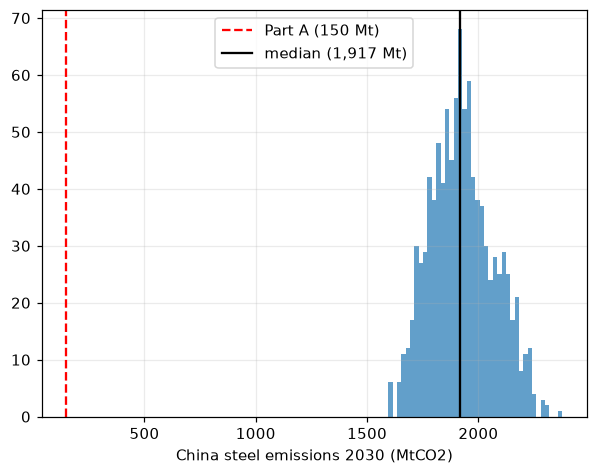

In [15]:
sim30 = simulate(1000, year=2030)
lo, med, hi, rel = interval(sim30["national"])
part_a_2030 = company_emissions.query("Year == 2030")["estimated_emissions_tCO2"].sum() / 1e6
print(f"2030 national emissions: median {med:,.0f} Mt, 90% interval [{lo:,.0f}, {hi:,.0f}] Mt, relative half-width {rel:.1%}")
print(f"Part A value 2030: {part_a_2030:,.0f} Mt  ->  simulation median is {med / part_a_2030:.1f}x larger")

plt.hist(sim30["national"], bins=40, color="tab:blue", alpha=0.7)
plt.axvline(part_a_2030, color="red", ls="--", label=f"Part A ({part_a_2030:,.0f} Mt)")
plt.axvline(med, color="k", label=f"median ({med:,.0f} Mt)")
plt.xlabel("China steel emissions 2030 (MtCO2)"); plt.legend(); plt.show()

**Your answer (Q8):**

**(a)** 2030 national emissions: **median 1,917 Mt**, **90% interval [1,710, 2,173] Mt**, relative half-width **12.1%**.

**(b)** The Part A value is only **150 Mt**, 12.8x below the simulation. The simulation is the credible one: it uses matched utilisation (~0.8, consistent with the official-implied 0.79) and gives about 1.9 Gt, close to what China's steel sector is generally estimated to emit. Part A divides the output of the few reporting plants by the capacity of all plants (B1: 10% coverage), hence the huge gap.

### Q9 [QUANT + QUAL] Which input matters most?

Run `simulate` twice: once varying **only the utilisation** (`vary_ef=False`) and once varying **only the emission factor** (`vary_util=False`). For each, give the relative half-width for 2030. Which input creates more of the uncertainty? Could **more data** reduce it?

In [16]:
only_util = simulate(1000, year=2030, vary_ef=False)
only_ef = simulate(1000, year=2030, vary_util=False)
for name, s in [("utilisation only", only_util), ("emission factor only", only_ef), ("both", sim30)]:
    lo_, med_, hi_, rel_ = interval(s["national"])
    print(f"{name:<22} median {med_:,.0f} Mt | 90% [{lo_:,.0f}, {hi_:,.0f}] | relative half-width {rel_:.1%}")

utilisation only       median 1,894 Mt | 90% [1,836, 1,954] | relative half-width 3.1%
emission factor only   median 1,935 Mt | 90% [1,728, 2,157] | relative half-width 11.1%
both                   median 1,917 Mt | 90% [1,710, 2,173] | relative half-width 12.1%


**Your answer (Q9):**

Relative half-width in 2030: **3.1%** with utilisation only, **11.1%** with the emission factor only (12.1% with both). The **emission factor** creates most of the uncertainty (note that its ranges are assumed values). More data could reduce both, since they are epistemic: more reporting plants narrow the utilisation range, and measured plant-level intensities would narrow the emission-factor range, which is where data would help most.

### Q10 [QUANT + QUAL] Companies: can you say who is number one?

Using `by_company` of your 2030 run: (a) for the **top 3 companies by median**, give the median and the 90% interval; (b) compute the probability that the #1 company emits **more than** the #2 (fraction of simulations); (c) what would you write in a report instead of "Company X is the largest emitter"?

In [17]:
bc = sim30["by_company"]
top3 = bc.median().nlargest(3).index
summary = pd.DataFrame({"median": bc[top3].median(), "p5": bc[top3].quantile(0.05), "p95": bc[top3].quantile(0.95)})
display(summary)

first, second = top3[0], top3[1]
p_first = (bc[first] > bc[second]).mean()
print(f"P({first} > {second}) = {p_first:.1%}")
print(f"correlation of the two draws: {np.corrcoef(bc[first], bc[second])[0, 1]:.2f}")

,median,p5,p95
Angang Steel Co Ltd [100.0%],56.24,50.03,63.93
Baoshan Iron & Steel Co Ltd [100.0%],53.54,47.63,60.86
Beijing Shougang Co Ltd [100.0%],38.67,34.40,43.96


P(Angang Steel Co Ltd [100.0%] > Baoshan Iron & Steel Co Ltd [100.0%]) = 100.0%
correlation of the two draws: 1.00


**Your answer (Q10):**

**(a)** Top 3 by median (2030, MtCO2): Angang Steel **56.2** [50.0, 63.9]; Baoshan Iron & Steel **53.5** [47.6, 60.9]; Beijing Shougang **38.7** [34.4, 44.0].

**(b)** P(#1 > #2) = **100%**, but this is an artefact: both companies are BF-BOF and share the same utilisation and emission-factor draws (correlation 1.00), so only their capacity ratio matters. The model does not include plant-level errors or ownership uncertainty, so this certainty is not real.

**(c)** I would write: "Angang Steel and Baoshan Iron & Steel are the two largest emitters at roughly 50-60 MtCO2 each; the difference between them (about 5%) is within the uncertainty of the ownership and plant data, so we cannot rank them with confidence."

## B5. Is the interval honest? Test it

A 90% interval should contain the true value in about 90% of cases. We have one case where the truth is known: **official 2023 production**.

### Q11 [QUANT + QUAL] Does the official value fall inside?

Run `simulate(1000, year=2023)` and look at `national_prod` (Mt). (a) Give its 90% interval and say whether the official 2023 value (1,020 Mt) falls inside. (b) If not, what does this tell you about the interval, **even though it was computed correctly**? (c) What would you do about it?

In [18]:
sim23 = simulate(1000, year=2023)
lo, med, hi, rel = interval(sim23["national_prod"])
official_2023_mt = official_kt[2023] / 1000
print(f"2023 national production: median {med:,.0f} Mt, 90% interval [{lo:,.0f}, {hi:,.0f}] Mt")
print(f"official 2023 = {official_2023_mt:,.0f} Mt -> inside interval: {lo <= official_2023_mt <= hi}")
print(f"share of simulations below the official value: {(sim23['national_prod'] < official_2023_mt).mean():.1%}")

# back-test on every year with an official value
for y in official_kt:
    p5, p95 = np.percentile(simulate(1000, year=y)["national_prod"], [5, 95])
    print(y, f"90% interval [{p5:,.0f}, {p95:,.0f}] Mt | official {official_kt[y] / 1000:,.0f} Mt | inside: {p5 <= official_kt[y] / 1000 <= p95}")

2023 national production: median 1,032 Mt, 90% interval [995, 1,067] Mt
official 2023 = 1,019 Mt -> inside interval: True
share of simulations below the official value: 29.0%
2020 90% interval [1,038, 1,111] Mt | official 1,065 Mt | inside: True
2021 90% interval [1,035, 1,108] Mt | official 1,035 Mt | inside: True
2022 90% interval [1,023, 1,096] Mt | official 1,018 Mt | inside: False
2023 90% interval [995, 1,067] Mt | official 1,019 Mt | inside: True


**Your answer (Q11):**

**(a)** 2023 production: 90% interval **[995, 1,067] Mt** (median 1,032 Mt). The official 1,019 Mt **falls inside** (29% of simulations are below it).

**(b)** One hit does not prove that the interval is honest: a 90% interval should miss 1 year in 10, and in the back-test of 2020-2023 it contains the official value in 3 of 4 years (2021 only just, 2022 just misses). The hits also partly hold by construction: capacity is inflated by retired/cancelled records without an end date (Q1), but the matched utilisation is computed on that same inflated capacity (52 of 103 matched plant-years include a non-operating record; on operating capacity only, BF-BOF utilisation would be 0.97 instead of 0.82), so the two errors cancel. The interval only reflects sampling and emission-factor noise, not this structural bias nor the selection of reporting plants (Q6), so it is probably too narrow.

**(c)** Back-test on more years and countries, fix the capacity base (retired plants without date) and add the bias of reporting plants as an extra uncertainty, instead of trusting the interval as it is.

## B6. Scenarios

A **scenario** is a "what if" story. We do **not** attach a probability to it; we run each one through the same simulation and compare.

| Scenario | Story | How |
|---|---|---|
| **S0** | no change | as is |
| **S1** | **30% of BF-BOF capacity is retired** (by 2027, still true in 2030) | `bf_cap_mult=0.7` |
| **S2** | **steel demand drops**: utilisation 10% lower | `util_mult=0.9` |

### Q12 [QUANT + QUAL] Scenario gap vs interval width

(a) Run the three scenarios for 2030 and give the **median and 90% interval** of each. (b) Compare the **gap between** scenario medians with the **width of the interval** within a scenario. Which is bigger? (c) Why would it be misleading to average the three scenarios into one probability-weighted number?

,p5,median,p95,width
S0 no change,"1,710.01","1,917.31","2,173.27",463.26
S1 BF-BOF capacity -30%,"1,210.78","1,359.35","1,536.53",325.76
S2 utilisation -10%,"1,539.01","1,725.57","1,955.95",416.94


gap between scenario medians (S0 - S1, S0 - S2): 558 192 Mt


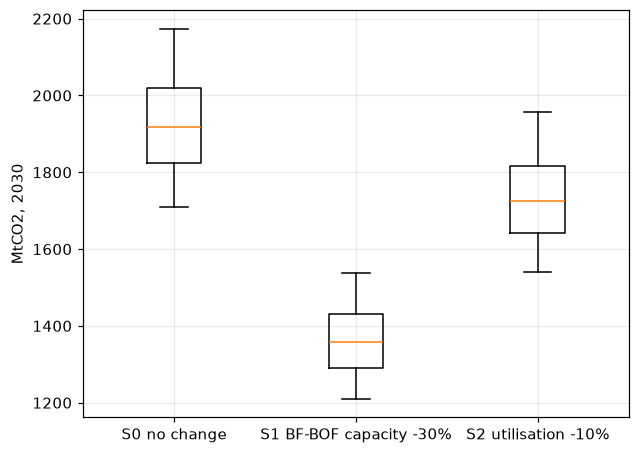

In [19]:
scenarios = {"S0 no change": {}, "S1 BF-BOF capacity -30%": {"bf_cap_mult": 0.7}, "S2 utilisation -10%": {"util_mult": 0.9}}
scen = {name: simulate(1000, year=2030, **kw)["national"] for name, kw in scenarios.items()}

tab = pd.DataFrame({name: dict(zip(["p5", "median", "p95"], np.percentile(v, [5, 50, 95]))) for name, v in scen.items()}).T
tab["width"] = tab["p95"] - tab["p5"]
display(tab)
print("gap between scenario medians (S0 - S1, S0 - S2):",
      round(tab.loc["S0 no change", "median"] - tab.loc["S1 BF-BOF capacity -30%", "median"]),
      round(tab.loc["S0 no change", "median"] - tab.loc["S2 utilisation -10%", "median"]), "Mt")

plt.boxplot(list(scen.values()), tick_labels=list(scen), whis=(5, 95), showfliers=False)
plt.ylabel("MtCO2, 2030"); plt.show()

**Your answer (Q12):**

**(a)** 2030 (MtCO2, median [5%, 95%]): **S0** 1,917 [1,710, 2,173]; **S1** 1,359 [1,211, 1,537]; **S2** 1,726 [1,539, 1,956].

**(b)** S0-S1 gap is 558 Mt, bigger than the interval widths (463 / 326 Mt), so S1 is clearly separated. The S0-S2 gap is 192 Mt, smaller than the widths (463 / 417 Mt), so S2 overlaps with S0 and the statistical uncertainty is as large as the scenario effect.

**(c)** Scenarios are stories about choices, not events with known probabilities, so weights would be arbitrary. The average would be a number (~1,670 Mt) that no scenario produces and would hide how much depends on decisions.

## B7. Communicate

Words used by the IPCC for probabilities: **virtually certain** 99-100%, **very likely** 90-100%, **likely** 66-100%, **about as likely as not** 33-66%, **unlikely** 10-33%, **very unlikely** 1-10%, **exceptionally unlikely** 0-1%.

### Q13 [QUANT + QUAL] A probability, a word, and a note

(a) For each scenario, compute the probability that **2030 emissions exceed the 2023 median** (from your `simulate(..., year=2023)`) and give the matching word. (b) Write a note of **about 80 words** for a bank's risk committee about China's steel emissions in 2030. Include: the **median and 90% interval** (baseline), **one sentence on the scenarios**, the **biggest source of uncertainty**, **one limitation** of the model and **one recommended action**. Plain language, no jargon.

> **Hint.** `(draws > threshold).mean()`.

In [20]:
def ipcc_word(p):
    for bound, word in [(0.99, "virtually certain"), (0.90, "very likely"), (0.66, "likely"),
                        (0.33, "about as likely as not"), (0.10, "unlikely"), (0.01, "very unlikely")]:
        if p >= bound:
            return word
    return "exceptionally unlikely"

threshold = np.median(sim23["national"])
print(f"2023 median emissions (threshold): {threshold:,.0f} Mt")
for name, draws in scen.items():
    p = (draws > threshold).mean()
    print(f"{name:<26} P(2030 > 2023 median) = {p:.1%} -> {ipcc_word(p)}")

lo, med, hi, _ = interval(scen["S0 no change"])
print(f"baseline 2030: median {med:,.0f} Mt, 90% interval [{lo:,.0f}, {hi:,.0f}] Mt")

2023 median emissions (threshold): 1,933 Mt
S0 no change               P(2030 > 2023 median) = 44.8% -> about as likely as not
S1 BF-BOF capacity -30%    P(2030 > 2023 median) = 0.0% -> exceptionally unlikely
S2 utilisation -10%        P(2030 > 2023 median) = 7.4% -> very unlikely
baseline 2030: median 1,917 Mt, 90% interval [1,710, 2,173] Mt


**Your answer (Q13):**

**(a)** Threshold = 2023 median, **1,933 Mt**. P(2030 emissions > threshold): **S0 44.8%** (about as likely as not); **S1 0.0%** (exceptionally unlikely); **S2 7.4%** (very unlikely).

**(b)** Note for the risk committee:

> We expect China's steel industry to emit about 1,900 million tonnes of CO2 in 2030, with a 90% range of 1,700 to 2,170 million. It is about as likely as not to be above the 2023 level. If 30% of blast furnace capacity closes, emissions fall to about 1,360 million; a 10% drop in demand gives about 1,730 million. The biggest uncertainty is the CO2 emitted per tonne of steel. Limitation: our data cover few plants' production. Action: ask borrowers for measured emissions and production.